In [10]:
import sys

# this kernel's numpy (2.1.2) + uproot (5.1.2) combo raises OverflowError reading JetClass
# .root files - prepend the deps folder with compatible versions before anything imports numpy
deps_path = "/home/users/w/wozniak/.local/ntp4jets-deps"
if deps_path not in sys.path:
    sys.path.insert(0, deps_path)

import pyrootutils

pyrootutils.setup_root(__file__ if "__file__" in dir() else ".", indicator=".project-root", pythonpath=True)

import hydra
import numpy as np
import torch
import matplotlib.pyplot as plt
from omegaconf import OmegaConf

from gabbro.models.backbone_multihead import BackboneMultiHeadLightning

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device


device(type='cuda')

## instantiate dataloader and load data

In [11]:
from hydra import compose, initialize_config_dir
from hydra.core.global_hydra import GlobalHydra

# `example_experiment_backbone_and_head_allfeat_mpm.yaml`'s `defaults:` list overrides
# `/feature_dict` (-> feature_dict_all_without_cuts.yaml) and `/data` (-> iter_dataset_jetclass_all_types)
# - OmegaConf.load can't apply those group overrides or resolve `${feature_dict}` interpolations,
# only Hydra's compose can. Build the config the same way `train.py`'s `@hydra.main` does.
# This experiment also sets `dataset_kwargs_common.token_id_cfg`, so the dataloader reads
# pre-tokenized *.parquet files (not raw .root) - point data_dir at the tokenized dataset dir
# that's actually accessible here (same one used for training this checkpoint).
GlobalHydra.instance().clear()
with initialize_config_dir(
    config_dir="/home/users/w/wozniak/dev/enhancing-ntp4jets/configs", version_base=None
):
    cfg = compose(
        config_name="train",
        overrides=[
            "experiment=example_experiment_backbone_and_head_allfeat_mpm",
            "data.data_dir=/srv/beegfs/scratch/groups/rodem/lumea/datasets/JetClass/Pythia/"
            "cont_alfa_tokenized_allfeat/2026-08-04_14-03-40_gpu024_EquestrianSymbol",
        ],
    )

print(OmegaConf.to_yaml(cfg.data.dataset_kwargs_common.feature_dict, resolve=True))


part_pt:
  multiply_by: 1
  subtract_by: 1.8
  func: signed_log
  inv_func: signed_exp
part_etarel:
  multiply_by: 3
part_phirel:
  multiply_by: 3
part_mass:
  clip_min_input_space: 0
part_charge: null
part_isChargedHadron: null
part_isNeutralHadron: null
part_isPhoton: null
part_isElectron: null
part_isMuon: null
part_d0val:
  func: signed_log
  inv_func: signed_exp
part_dzval:
  func: signed_log
  inv_func: signed_exp
part_d0err: null
part_dzerr: null



In [12]:
N_JETS = 100_000

# restrict the train split to QCD only, single file (ZJetsToNuNu_* files have 100K jets each,
# so one file already gives us ~100K jets) - everything else (feature_dict, cuts, padding,
# labels_to_load) stays exactly as used for training
cfg.data.dataset_kwargs_train.files_dict = {
    "QCD": cfg.data.dataset_kwargs_train.files_dict.QCD
}
cfg.data.dataset_kwargs_train.max_n_files_per_type = 1
cfg.data.dataset_kwargs_common.labels_to_load = ["label_QCD"]

datamodule = hydra.utils.instantiate(cfg.data)
datamodule.setup(stage="fit")

train_dataloader = datamodule.train_dataloader()


Parameter seed is present in both dataset_kwargs_common (value=12345) and dataset_kwargs_train(value=42). Using the value from dataset_kwargs_train.
Parameter seed is present in both dataset_kwargs_common (value=12345) and dataset_kwargs_val(value=1). Using the value from dataset_kwargs_val.
Parameter seed_shuffle_data is present in both dataset_kwargs_common (value=12345) and dataset_kwargs_val(value=1). Using the value from dataset_kwargs_val.
Parameter seed_shuffle_data is present in both dataset_kwargs_common (value=12345) and dataset_kwargs_test(value=42). Using the value from dataset_kwargs_test.
Parameter random_seed_for_per_file_shuffling is present in both dataset_kwargs_common (value=12345) and dataset_kwargs_val(value=None). Using the value from dataset_kwargs_val.
random_seed_for_per_file_shuffling is only used if load_only_once is True.
n_files_at_once=10 is larger than the number of files in the dataset (1).
Setting n_files_at_once to 1.
shuffle_files is False. This means

In [ ]:
part_features_list = []
part_mask_list = []
jet_features_list = []

n_collected = 0
for batch in train_dataloader:
    part_features_list.append(batch["part_features"])
    part_mask_list.append(batch["part_mask"])
    jet_features_list.append(batch["jet_features"])
    n_collected += batch["part_features"].shape[0]
    if n_collected >= N_JETS:
        break

jetclass_part_features = torch.cat(part_features_list)[:N_JETS].numpy()
jetclass_part_mask = torch.cat(part_mask_list)[:N_JETS].numpy()
jetclass_jet_features = torch.cat(jet_features_list)[:N_JETS].numpy()

print(f"Collected {jetclass_part_features.shape[0]} QCD jets.")
print(f"part_features shape: {tuple(jetclass_part_features.shape)}")
print(f"part_mask shape:     {tuple(jetclass_part_mask.shape)}")
print(f"jet_features shape:  {tuple(jetclass_jet_features.shape)}")


## Load ~100K jets from the Aspen Open Jets (AOJ) dataset using `dataset_type="aoj"`

Reuses the same config machinery as above, but switches the dataloader to the
`read_cms_open_data_file` codepath (single AOJ h5 file). Note: that reader only
exposes `part_pt`/`part_eta`/`part_phi`/`part_etarel`/`part_phirel` at the particle
level (no charge, PID flags, mass, or impact-parameter fields like the JetClass
reader has), and it doesn't load jet-level features at all - so the feature_dict
is restricted to `feature_dict_kin_massless_without_cuts.yaml` accordingly.

In [ ]:
GlobalHydra.instance().clear()
with initialize_config_dir(
    config_dir="/home/users/w/wozniak/dev/enhancing-ntp4jets/configs", version_base=None
):
    cfg_aoj = compose(
        config_name="train",
        overrides=[
            "experiment=example_experiment_backbone_and_head_allfeat_mpm",
            "feature_dict=feature_dict_kin_massless_without_cuts",
        ],
    )

AOJ_FILE = "/srv/beegfs/scratch/groups/rodem/lumea/datasets/aspenJets/RunG_batch0.h5"

# switch off the tokenized-parquet codepath and jetclass-only extras, point at the AOJ file
cfg_aoj.data.dataset_kwargs_common.dataset_type = "aoj"
cfg_aoj.data.dataset_kwargs_common.token_id_cfg = None
cfg_aoj.data.dataset_kwargs_common.feature_dict_labels_particles = None
cfg_aoj.data.dataset_kwargs_common.feature_dict_jet = None
cfg_aoj.data.dataset_kwargs_common.labels_to_load = ["label_QCD"]

cfg_aoj.data.data_dir = "/srv/beegfs/scratch/groups/rodem/lumea/datasets/aspenJets"
# `setup(stage="fit")` also builds the val dataset, so point that at the same single file too
cfg_aoj.data.dataset_kwargs_train.files_dict = {"QCD": [AOJ_FILE]}
cfg_aoj.data.dataset_kwargs_train.max_n_files_per_type = 1
cfg_aoj.data.dataset_kwargs_val.files_dict = {"QCD": [AOJ_FILE]}
cfg_aoj.data.dataset_kwargs_val.max_n_files_per_type = 1

print(OmegaConf.to_yaml(cfg_aoj.data.dataset_kwargs_common.feature_dict, resolve=True))

part_pt:
  multiply_by: 1
  subtract_by: 1.8
  func: signed_log
  inv_func: signed_exp
part_etarel:
  multiply_by: 3
part_phirel:
  multiply_by: 3



In [ ]:
datamodule_aoj = hydra.utils.instantiate(cfg_aoj.data)
datamodule_aoj.setup(stage="fit")

train_dataloader_aoj = datamodule_aoj.train_dataloader()

Parameter seed is present in both dataset_kwargs_common (value=12345) and dataset_kwargs_train(value=42). Using the value from dataset_kwargs_train.
Parameter seed is present in both dataset_kwargs_common (value=12345) and dataset_kwargs_val(value=1). Using the value from dataset_kwargs_val.
Parameter seed_shuffle_data is present in both dataset_kwargs_common (value=12345) and dataset_kwargs_val(value=1). Using the value from dataset_kwargs_val.
Parameter seed_shuffle_data is present in both dataset_kwargs_common (value=12345) and dataset_kwargs_test(value=42). Using the value from dataset_kwargs_test.
Parameter random_seed_for_per_file_shuffling is present in both dataset_kwargs_common (value=12345) and dataset_kwargs_val(value=None). Using the value from dataset_kwargs_val.
random_seed_for_per_file_shuffling is only used if load_only_once is True.
n_files_at_once=10 is larger than the number of files in the dataset (1).
Setting n_files_at_once to 1.
shuffle_files is False. This means

In [ ]:
N_JETS_AOJ = 100_000

aoj_part_features_list = []
aoj_part_mask_list = []

n_collected = 0
for batch in train_dataloader_aoj:
    aoj_part_features_list.append(batch["part_features"])
    aoj_part_mask_list.append(batch["part_mask"])
    n_collected += batch["part_features"].shape[0]
    if n_collected >= N_JETS_AOJ:
        break

aoj_part_features = torch.cat(aoj_part_features_list)[:N_JETS_AOJ].numpy()
aoj_part_mask = torch.cat(aoj_part_mask_list)[:N_JETS_AOJ].numpy()

print(f"Collected {aoj_part_features.shape[0]} AOJ jets.")
print(f"part_features shape: {tuple(aoj_part_features.shape)}")
print(f"part_mask shape:     {tuple(aoj_part_mask.shape)}")

Collected 100000 AOJ jets.
part_features shape: (100000, 100, 3)
part_mask shape:     (100000, 100)


## Compare input feature distributions (JetClass vs. AOJ)

For each particle feature present in both feature dicts, plot a histogram of the
values used for real (non-padded) particles, following the same plotting call as
in `scripts/evaluate_aspen_distributions.py`.

Comparing common features: ['part_pt', 'part_etarel', 'part_phirel']


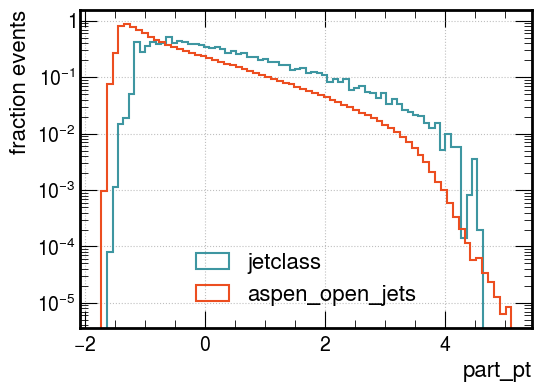

writing figure to analysis/aspen_jets/part_pt__jetclass_vs_aoj.pdf


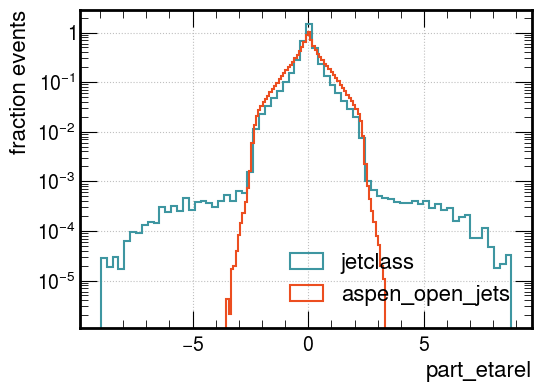

writing figure to analysis/aspen_jets/part_etarel__jetclass_vs_aoj.pdf


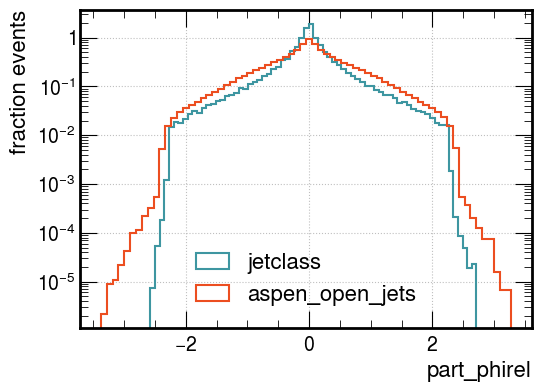

writing figure to analysis/aspen_jets/part_phirel__jetclass_vs_aoj.pdf


In [ ]:
import os
import sys

deps_path = "/home/users/w/wozniak/.local/ntp4jets-deps"
if deps_path not in sys.path:
    sys.path.insert(0, deps_path)

import heputl.plotting.oneD as heplt

output_dir = "analysis/aspen_jets"
os.makedirs(output_dir, exist_ok=True)

jetclass_feature_names = list(cfg.data.dataset_kwargs_common.feature_dict.keys())
aoj_feature_names = list(cfg_aoj.data.dataset_kwargs_common.feature_dict.keys())
common_features = [feat for feat in aoj_feature_names if feat in jetclass_feature_names]
print(f"Comparing common features: {common_features}")

for feat in common_features:
    # skip particle index 0: the tokenized-data config (`token_id_cfg.add_padded_particle_features_start`)
    # prepends an all-zero "start token" particle to every jet, which isn't a real constituent
    jetclass_idx = jetclass_feature_names.index(feat)
    jetclass_flat = jetclass_part_features[:, 1:, jetclass_idx][jetclass_part_mask[:, 1:]]

    aoj_idx = aoj_feature_names.index(feat)
    aoj_flat = aoj_part_features[..., aoj_idx][aoj_part_mask]

    heplt.plot_feature_hist_for_n_samples(
        data=[jetclass_flat, aoj_flat],
        sample_names=["jetclass", "aspen_open_jets"],
        xlabel=feat,
        bins=70,
        plot_name=f"{feat}__jetclass_vs_aoj",
        fig_dir=output_dir,
        show_plt=True,
        legend_outside=False,
        fig_size=(6.0, 4.5),
    )

In [ ]:
etarel_idx = jetclass_feature_names.index("part_etarel")

# raw (pre `multiply_by: 3`) etarel per particle, masked to real (non start-token) particles only
raw_etarel = jetclass_part_features[:, 1:, etarel_idx] / 3
mask = jetclass_part_mask[:, 1:]

outlier_mask = mask & (np.abs(raw_etarel) > 0.8)  # outside the R=0.8 cone
n_outliers = outlier_mask.sum()
print(f"Particles with |raw etarel| > 0.8: {n_outliers} / {mask.sum()} ({100 * n_outliers / mask.sum():.3f}%)")

# where (sequence position, i.e. particle index within the jet) do the outliers sit?
outlier_jet_idx, outlier_pos_idx = np.where(outlier_mask)
print("Outlier particle-index (position within jet) distribution:")
print(np.unique(outlier_pos_idx, return_counts=True))

# how many real (masked) particles does each outlier's jet have, and is the outlier the last one?
n_real_per_jet = mask.sum(axis=1)
is_last_particle = outlier_pos_idx == (n_real_per_jet[outlier_jet_idx] - 1)
print(f"Fraction of outliers that are the LAST real particle in their jet: {is_last_particle.mean():.3f}")

print("Example raw etarel/phirel values for a few outlier particles:")
phirel_idx = jetclass_feature_names.index("part_phirel")
raw_phirel = jetclass_part_features[:, 1:, phirel_idx] / 3
for j, p in list(zip(outlier_jet_idx, outlier_pos_idx))[:10]:
    print(f"  jet {j}, pos {p} (n_real={n_real_per_jet[j]}): etarel={raw_etarel[j, p]:.3f}, phirel={raw_phirel[j, p]:.3f}")


The history saving thread hit an unexpected error (OperationalError('disk I/O error')).History will not be written to the database.
Particles with |raw etarel| > 0.8: 14010 / 3520379 (0.398%)
Outlier particle-index (position within jet) distribution:
(array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33,
       34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50,
       51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67,
       68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84,
       85, 86, 87, 88, 89, 90, 91, 93, 94, 95, 97]), array([421, 442, 451, 465, 402, 458, 454, 418, 439, 438, 452, 451, 413,
       433, 383, 398, 408, 345, 331, 331, 292, 304, 290, 289, 266, 248,
       218, 237, 218, 208, 204, 203, 181, 176, 154, 147, 116, 130, 129,
       110, 133, 109,  95,  79,  89,  75,  74,  61,  77,  62,  54,  46,
        47,  35,  63,  29,  35, 

## Sanity check: raw (pre-tokenization) JetClass vs. AOJ

Everything above goes through the VQ-VAE tokenized-parquet codepath for JetClass. To rule out
the tokenization/reconstruction pipeline entirely, this section loads JetClass directly from the
original `.root` files (`read_jetclass_file`, no VQ-VAE involved) and compares it against AOJ,
with all 14 particle features from `feature_dict_all_without_cuts.yaml` computed for both.

AOJ's raw h5 reader (`read_cms_open_data_file`) only exposes 5 of these (pt/eta/phi/etarel/phirel).
The other 9 (charge, PID one-hot flags, impact parameters) are computed manually below, following
the same `np_to_ak` -> `ak.zip(..., "Momentum4D")` -> `ak.sum` -> `deltaeta`/`deltaphi` pattern
used in `gabbro/data/loading.py`, extended to decode the raw `PFCands` columns
`[px, py, pz, E, d0, d0Err, dz, dzErr, charge, pdgId, PUPPI weight]`.

Note: AOJ encodes d0/dz (and their errors) as `-1` for neutral particles (no track), while
JetClass uses `0` - a labeling-convention difference, not a physics one. Expect a spurious spike
at `-1` in the AOJ-only `part_d0val`/`part_dzval`/`part_d0err`/`part_dzerr` histograms.

In [ ]:
import awkward as ak
import h5py
import numpy as np

from gabbro.data.loading import read_jetclass_file
from gabbro.utils.arrays import np_to_ak

N_JETS_RAW = 100_000

# the 14 particle features from configs/feature_dict/feature_dict_all_without_cuts.yaml
FEATURE_LIST = [
    "part_pt",
    "part_etarel",
    "part_phirel",
    "part_mass",
    "part_charge",
    "part_isChargedHadron",
    "part_isNeutralHadron",
    "part_isPhoton",
    "part_isElectron",
    "part_isMuon",
    "part_d0val",
    "part_dzval",
    "part_d0err",
    "part_dzerr",
]

# raw (untokenized) JetClass QCD file - same jet type used elsewhere in this notebook
JETCLASS_RAW_FILE = (
    "/srv/beegfs/scratch/groups/rodem/lumea/datasets/JetClass/Pythia/"
    "train_100M/ZJetsToNuNu_000.root"
)
AOJ_FILE = "/srv/beegfs/scratch/groups/rodem/lumea/datasets/aspenJets/RunG_batch0.h5"

In [ ]:
jetclass_raw_ak, _, _ = read_jetclass_file(
    JETCLASS_RAW_FILE,
    particle_features=FEATURE_LIST,
    jet_features=None,
    labels=["label_QCD"],
    return_p4=False,
    n_load=N_JETS_RAW,
)

print(f"Loaded {len(jetclass_raw_ak)} raw (untokenized) JetClass jets.")
print(f"Fields: {jetclass_raw_ak.fields}")

In [ ]:
with h5py.File(AOJ_FILE, "r") as f:
    pf_cands = f["PFCands"][:N_JETS_RAW]  # (N, 150, 11)

# same real-particle convention as `read_cms_open_data_file`: nonzero energy
pfcands_ak = np_to_ak(
    pf_cands,
    names=["px", "py", "pz", "E", "d0val", "d0err", "dzval", "dzerr", "charge", "pdgid", "puppi_wt"],
    mask=pf_cands[:, :, 3] != 0,
)

p4 = ak.zip(
    {"px": pfcands_ak.px, "py": pfcands_ak.py, "pz": pfcands_ak.pz, "E": pfcands_ak.E},
    with_name="Momentum4D",
)
p4_jet = ak.sum(p4, axis=1)

abs_pdgid = np.abs(pfcands_ak.pdgid)
is_electron = abs_pdgid == 11
is_muon = abs_pdgid == 13
is_photon = pfcands_ak.pdgid == 22
is_charged_hadron = (pfcands_ak.charge != 0) & ~is_electron & ~is_muon
is_neutral_hadron = (pfcands_ak.charge == 0) & ~is_photon

aoj_raw_ak = ak.Array(
    {
        "part_pt": p4.pt,
        "part_etarel": p4.deltaeta(p4_jet),
        "part_phirel": p4.deltaphi(p4_jet),
        "part_mass": p4.mass,
        "part_charge": pfcands_ak.charge,
        "part_isChargedHadron": ak.values_astype(is_charged_hadron, "float32"),
        "part_isNeutralHadron": ak.values_astype(is_neutral_hadron, "float32"),
        "part_isPhoton": ak.values_astype(is_photon, "float32"),
        "part_isElectron": ak.values_astype(is_electron, "float32"),
        "part_isMuon": ak.values_astype(is_muon, "float32"),
        "part_d0val": pfcands_ak.d0val,
        "part_dzval": pfcands_ak.dzval,
        "part_d0err": pfcands_ak.d0err,
        "part_dzerr": pfcands_ak.dzerr,
    }
)[FEATURE_LIST]

print(f"Loaded {len(aoj_raw_ak)} AOJ jets (manually computed features).")
print(f"Fields: {aoj_raw_ak.fields}")

In [ ]:
import os
import sys

deps_path = "/home/users/w/wozniak/.local/ntp4jets-deps"
if deps_path not in sys.path:
    sys.path.insert(0, deps_path)

import heputl.plotting.oneD as heplt

output_dir = "analysis/aspen_jets"
os.makedirs(output_dir, exist_ok=True)

for feat in FEATURE_LIST:
    jetclass_flat = ak.flatten(jetclass_raw_ak[feat]).to_numpy()
    aoj_flat = ak.flatten(aoj_raw_ak[feat]).to_numpy()

    heplt.plot_feature_hist_for_n_samples(
        data=[jetclass_flat, aoj_flat],
        sample_names=["jetclass (raw, untokenized)", "aspen_open_jets"],
        xlabel=feat,
        bins=70,
        plot_name=f"{feat}__raw_jetclass_vs_aoj",
        fig_dir=output_dir,
        show_plt=True,
        legend_outside=False,
        fig_size=(6.0, 4.5),
    )